# NOGSE fits with trapezoidal lobes after removing the magnitude noise floor

Companion of `nogse_fits_trapezoidal_lobes.ipynb` for the free-water phantom (set v2.00.1, $128\times128$). It reads the same rows of `master.long.parquet`, uses the same model (exact $b$ of the played trapezoids, `nogse_trapezoid_b_per_g2`) and the same one-parameter fit of $D_0$ with $M_0=1$. **The only change is that the noise floor of the magnitude images is removed from the normalised signals before fitting** (method of `docs/papers/metrics_note_detailed.pdf`, Section 3, step 4). The uncorrected fit is repeated here so that both can be compared on the same footing. Outputs go to `signal_analysis/results/trapezoidal_lobes_noise_floor/sub-<SUB>/`; the outputs of the original notebook are not touched.

## Why a floor appears

The images are magnitudes, $|A + \text{complex noise}|$. The noise does not average to zero: where the true signal $A$ is small, the mean magnitude stays on a floor $F$ (scanner units). Averaging over the voxels of the ROI reduces the scatter of that floor, not its value. A good approximation of the mean magnitude is

$$S=\sqrt{A^2+F^2},\qquad F=\kappa\,\sigma,$$

exact at $A=0$ and at $A\gg\sigma$, where $\sigma$ is the noise per real/imaginary channel. For a sum-of-squares combination of $n$ effective receive channels $\kappa=\sqrt2\,\Gamma(n+\tfrac12)/\Gamma(n)\approx\sqrt{2n}$ (1.25 for $n=1$, 3.94 for $n=8$, 7.8 for $n=30$). These data were acquired with the 64-channel head/neck coil and "Sum of Squares" coil combination, so the floor is several times $\sigma$.

Applying the same relation to $S$ and to $S_0$ and inverting,

$$a=\frac{A}{A_0}=\frac{\sqrt{\max(S^2-F^2,\,0)}}{\sqrt{S_0^2-F^2}}=\frac{\sqrt{\max(s^2-c^2,\,0)}}{\sqrt{1-c^2}},\qquad s=\frac{S}{S_0},\quad c=\frac{F}{S_0}.$$

## How $F$ is measured

In free water every spin decays, so wherever the predicted attenuation is negligible the measured mean **is** the floor. Steps:

1. Reference $D_0$: the uncorrected fit restricted to points with $s\ge$ `FLOOR_FREE_MIN_SIGNAL` (the floor changes those points by less than $c^2/2s\approx0.003$).
2. Plateau points: those whose predicted attenuation with that $D_0$ is below `PLATEAU_MAX_SIGNAL`. In this set they are the Hahn points at $T=65$ ms with $G\ge49$ mT/m.
3. $F$ = mean of `value` (scanner units) over the plateau points. One $F$ for all series: same protocol, same receiver and the same $S_0$ to 0.1 %. $c=F/S_0$ then differs per series only through $S_0$.

Two independent checks are in the notebook: (i) a joint fit of all curves with the floor inside the model ($D_0$ and $c$ free, no plateau selection), and (ii) a quadrature floor against an additive non-decaying term, which a free-water phantom should not have. A third, image-based check ($\kappa=F/\sigma$ with $\sigma$ from the two b0 volumes) is in `nogse_d0_pixel_maps_noise_floor.ipynb`.

## What the contrast peak should be with $x_{Hahn}=5$ ms

For free diffusion each series is $M=e^{-k\,G^2D_0}$, so with $u=k_{Hahn}G^2D_0$ and $r=k_{CPMG}/k_{Hahn}$ the contrast is $\Delta M=e^{-ru}-e^{-u}$. Setting $d\Delta M/du=0$:

$$u^*=\frac{\ln(1/r)}{1-r},\qquad H(r)=\Delta M(u^*)=(1-r)\,r^{\,r/(1-r)}.$$

Only for an ideal Hahn limit ($x\to0$) with rectangular lobes is $r=1/N^2=1/4$ and $H=4^{-1/3}-4^{-4/3}=0.4725$ for every $T$. Here the Hahn series has $x=5$ ms and 1.2 ms ramps, so $r$ = 0.38, 0.34, 0.32, 0.30 at $T$ = 30, 40, 50, 65 ms and the expected peaks are **0.341, 0.378, 0.399, 0.417**, rising with $T$ because $x/T$ falls. The fitted model already contains this (it uses $x=5$ ms); the 0.4725 rule does not apply to these series.

In [12]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import least_squares, minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('Project root not found.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from fitting.b_from_g import nogse_trapezoid_b_per_g2
from models.model_fitting import _GYRO

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)

## Configuration

Same data selection as the original notebook. `MODEL_NAME` is the original model; outputs go to `OUTPUT_NAME`. `FLOOR_FREE_MIN_SIGNAL` and `PLATEAU_MAX_SIGNAL` define the reference fit and the plateau points (see above). `SESSION_ID` is the BIDS session (for PHANTOM-3 the long session labels, e.g. the AUTOG one; the cell lists the available ones if it does not exist). `FLOOR_ROIS` are the free-water ROIs whose plateau gives $F$ (`None`: the analysed ROI itself, as before); `FLOOR_F_OVERRIDE` imposes $F$ in scanner units. Outputs go to a `roi-<ROI>` subfolder, so that every ROI keeps its own figures and tables.

In [13]:
MODEL_NAME = 'trapezoidal_lobes'
OUTPUT_NAME = 'trapezoidal_lobes_noise_floor'
ANALYSIS_TAG = 'den_gr--manual'  # alternative: 'raw--manual'
SUB = 'PHANTOM-3'
SESSION_ID = '20261026NOGSEV2001FOV220M128SL01R1G070AUTOG'  # PHANTOM-1/2: 'T0'
ROI = 'water2'  # analysed ROI, e.g. 'water1', 'water2', 'fiber1', 'fiber2'
STAT = 'avg'
D0_BOUNDS_MM2_S = (1e-4, 1e-2)
FLOOR_FREE_MIN_SIGNAL = 0.2  # reference D0 only from points with S/S0 >= 0.2
PLATEAU_MAX_SIGNAL = 0.003   # plateau points: predicted attenuation below 0.3 %
FLOOR_ROIS = ['water1', 'water2']  # free-water ROIs that give F; None: the analysed ROI (PHANTOM-1/2: None)
FLOOR_F_OVERRIDE = None      # scanner units; set it to skip the plateau measurement
IDEAL_PEAK = 4 ** (-1 / 3) - 4 ** (-4 / 3)  # 0.4725: ideal Hahn limit, rectangular lobes, N = 2

MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
OUTPUT_ROOT = REPO_ROOT / 'results' / OUTPUT_NAME / f'sub-{SUB}' / f'ses-{SESSION_ID}' / f'roi-{ROI}'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIRECTION_DIR = OUTPUT_ROOT / 'contrasts_by_direction'
CONTRAST_TIME_DIR = OUTPUT_ROOT / 'contrasts_by_time'
FLOOR_DIR = OUTPUT_ROOT / 'noise_floor'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIRECTION_DIR, CONTRAST_TIME_DIR, FLOOR_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

master = pd.read_parquet(MASTER_PATH)
available_subjects = sorted(master['subj'].astype(str).unique())
if SUB not in available_subjects:
    raise ValueError(f'SUB={SUB!r} is not in the master. Available: {available_subjects}')
subject_rows = master.loc[master['subj'].astype(str) == SUB]
available_sessions = sorted(subject_rows['session_id'].dropna().astype(str).unique())
if SESSION_ID not in available_sessions:
    raise ValueError(f'SESSION_ID={SESSION_ID!r} is not in the master for {SUB}. Available: {available_sessions}')
session_rows = subject_rows.loc[(subject_rows['session_id'].astype(str) == SESSION_ID) &
                                (subject_rows['stat'].astype(str) == STAT) &
                                (subject_rows['type'].astype(str).str.upper().isin(['CPMG', 'HAHN']))]
available_rois = sorted(session_rows['roi'].astype(str).unique())
missing_rois = [name for name in [ROI, *(FLOOR_ROIS or [])] if name not in available_rois]
if missing_rois:
    raise ValueError(f'ROIs {missing_rois} have no CPMG/HAHN rows in {SUB}, {SESSION_ID}. Available: {available_rois}')

NUMERIC = ['td_ms', 'TN', 'N', 'x', 'ramp_time_ms', 'g', 'bvalue', 'b_step', 'value', 'S0', 'value_norm']


def select_curves(roi):
    rows = session_rows.loc[session_rows['roi'].astype(str) == roi].copy()
    rows['type'] = rows['type'].astype(str).str.upper()
    rows['direction'] = rows['direction'].astype(str)
    rows['roi'] = rows['roi'].astype(str)
    for column in NUMERIC:
        rows[column] = pd.to_numeric(rows[column], errors='coerce')
    return rows.dropna(subset=NUMERIC)


data = select_curves(ROI)
if not np.allclose(data['TN'], data['td_ms']):
    raise ValueError('TN and td_ms differ: check the parameter table.')

print('Model:', MODEL_NAME, '| subject:', SUB, '| session:', SESSION_ID, '| ROI:', ROI, '| tag:', ANALYSIS_TAG)
print('Output:', OUTPUT_ROOT)
display(data.groupby(['type', 'td_ms']).agg(n=('value', 'size'), S0=('S0', 'first'), x_ms=('x', 'first')).reset_index())

Model: trapezoidal_lobes | subject: PHANTOM-3 | session: 20261026NOGSEV2001FOV220M128SL01R1G070AUTOG | ROI: water2 | tag: den_gr--manual
Output: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/trapezoidal_lobes_noise_floor/sub-PHANTOM-3/ses-20261026NOGSEV2001FOV220M128SL01R1G070AUTOG/roi-water2


,type,td_ms,n,S0,x_ms
0,CPMG,30.0,33,279.573131,15.0
1,CPMG,40.0,33,270.629015,20.0
2,CPMG,50.0,33,269.956885,25.0
3,CPMG,65.0,33,269.519719,32.5
4,HAHN,30.0,33,276.386643,5.0
5,HAHN,40.0,33,270.172419,5.0
6,HAHN,50.0,33,269.646082,5.0
7,HAHN,65.0,33,269.510387,5.0


## Model and one-parameter fit

The same functions as `nogse_fits_trapezoidal_lobes.ipynb`.

In [14]:
def k_model(tn_ms, n_value, x_ms, ramp_ms):
    # s/mm^2 per (mT/m)^2 of the played trapezoidal waveform (exact b / G^2)
    return nogse_trapezoid_b_per_g2(N=n_value, TN_ms=tn_ms, x_ms=x_ms, ramp_time_ms=ramp_ms, gamma=_GYRO)


def signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    return np.exp(-k_model(tn_ms, n_value, x_ms, ramp_ms) * np.asarray(g_mT_m, float)**2 * d0_mm2_s)


def contrast_model(tn_ms, g_mT_m, n_value, x_cpmg_ms, x_hahn_ms, ramp_cpmg_ms, ramp_hahn_ms, d0_mm2_s):
    # Each series with its own ramp (since 2026-10-26 the Hahn series may have 2x the CPMG ramps).
    return (signal_model(tn_ms, g_mT_m, n_value, x_cpmg_ms, ramp_cpmg_ms, d0_mm2_s)
            - signal_model(tn_ms, g_mT_m, n_value, x_hahn_ms, ramp_hahn_ms, d0_mm2_s))


def fit_one_parameter(y, model):
    y = np.asarray(y, float)
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_MM2_S)

    def loss(log_d0):
        prediction = np.asarray(model(np.exp(log_d0)), float)
        return np.mean((y[valid] - prediction[valid]) ** 2)

    result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
    d0 = float(np.exp(result.x))
    prediction = np.asarray(model(d0), float)
    residual = y[valid] - prediction[valid]
    return {
        'D0_mm2_s': d0,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'n_points': int(valid.sum()),
        'ok': bool(result.success),
    }


def timing(curve):
    row = curve.iloc[0]
    return float(row['TN']), float(row['N']), float(row['x']), float(row['ramp_time_ms'])


def d0_label(d0):
    return f'$D_0$={d0 * 1e3:.3f} × 10$^{{-3}}$ mm²/s'


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')

## Measuring the floor

Reference $D_0$ (points with $s\ge0.2$), predicted attenuation of every point, plateau points and $F$. The table lists the plateau points per series; the last column is the scatter of $s$ among them, which shows how flat the plateau is.

The method assumes **free water**: only there is the plateau the floor. For a fibre ROI the plateau may be restricted signal that does not decay, so $F$ is measured on `FLOOR_ROIS` (water of the same session and image) and applied to the analysed ROI. The floor depends on the position (coil sensitivity), so this is an approximation; the table gives $F$ per floor ROI. For a fibre ROI the $D_0$ reference line of the next figure and Check 1 below describe an apparent free model only.

In [15]:
def reference_d0(curves):
    # median over the series of the D0 fitted to the points with s >= FLOOR_FREE_MIN_SIGNAL
    reference = []
    for _keys, curve in curves.groupby(['type', 'td_ms', 'direction'], sort=True):
        curve = curve.sort_values('g')
        tn_ms, n_value, x_ms, ramp_ms = timing(curve)
        keep = curve['value_norm'].to_numpy(float) >= FLOOR_FREE_MIN_SIGNAL
        g = curve['g'].to_numpy(float)[keep]
        fit = fit_one_parameter(curve['value_norm'].to_numpy(float)[keep],
                                lambda d0: signal_model(tn_ms, g, n_value, x_ms, ramp_ms, d0))
        reference.append(fit['D0_mm2_s'])
    return float(np.median(reference))


def predicted_attenuation(curves, d0_by_roi):
    return [signal_model(row.TN, row.g, row.N, row.x, row.ramp_time_ms, d0_by_roi[row.roi]) for row in curves.itertuples()]


D0_REFERENCE = reference_d0(data)  # analysed ROI: reference line of the figure below
data['a_predicted'] = predicted_attenuation(data, {ROI: D0_REFERENCE})

if FLOOR_F_OVERRIDE is not None:
    FLOOR_F = float(FLOOR_F_OVERRIDE)
    plateau = data.iloc[0:0]
    floor_source = 'FLOOR_F_OVERRIDE'
else:
    floor_rois = list(FLOOR_ROIS or [ROI])
    floor_data = pd.concat([select_curves(name) for name in floor_rois], ignore_index=True)
    floor_d0 = {name: reference_d0(curves) for name, curves in floor_data.groupby('roi')}
    floor_data['a_predicted'] = predicted_attenuation(floor_data, floor_d0)
    plateau = floor_data.loc[floor_data['a_predicted'] < PLATEAU_MAX_SIGNAL]
    if plateau.empty:
        raise ValueError(f'No plateau points in {floor_rois}: raise PLATEAU_MAX_SIGNAL or set FLOOR_F_OVERRIDE.')
    FLOOR_F = float(plateau['value'].mean())
    floor_source = f'plateau of {floor_rois}'
    for name, d0 in floor_d0.items():
        print(f'Reference D0 of {name} (s >= {FLOOR_FREE_MIN_SIGNAL}): {d0 * 1e3:.4f} x 1e-3 mm²/s')
if (data['S0'] <= FLOOR_F).any():
    raise ValueError(f'S0 of {ROI} is not above the floor F = {FLOOR_F:.2f}: its signal is noise.')

data['c_floor'] = FLOOR_F / data['S0']
data['value_norm_corr'] = (np.sqrt(np.clip(data['value']**2 - FLOOR_F**2, 0, None)) /
                           np.sqrt(data['S0']**2 - FLOOR_F**2))
n_below = int((data['value'] < FLOOR_F).sum())

print(f'Reference D0 of {ROI} (s >= {FLOOR_FREE_MIN_SIGNAL}): {D0_REFERENCE * 1e3:.4f} x 1e-3 mm²/s')
print(f'Floor F = {FLOOR_F:.2f} (scanner units) from {floor_source} ({len(plateau)} plateau points); '
      f'c = F/S0 of {ROI} = {FLOOR_F / data["S0"].mean():.4f}; points below the floor (set to 0): {n_below}')
if FLOOR_F / data['S0'].mean() > 0.5:
    print(f'WARNING: F/S0 > 0.5 in {ROI}: its signal sits mostly on the floor and the correction amplifies the noise.')
if not plateau.empty:
    display(plateau.groupby(['roi', 'type', 'td_ms']).agg(
        n=('value', 'size'), g_min=('g', 'min'), a_predicted_max=('a_predicted', 'max'),
        value_mean=('value', 'mean'), s_mean=('value_norm', 'mean'), s_sd=('value_norm', 'std')).reset_index())

floor_table = data.groupby(['type', 'td_ms']).agg(S0=('S0', 'first'), c_floor=('c_floor', 'first')).reset_index()
floor_table.insert(0, 'F_scanner_units', FLOOR_F)
floor_table.insert(1, 'F_source', floor_source)
floor_table.to_csv(TABLE_DIR / 'noise_floor.csv', index=False)

Reference D0 of water1 (s >= 0.2): 2.8690 x 1e-3 mm²/s
Reference D0 of water2 (s >= 0.2): 2.6871 x 1e-3 mm²/s
Reference D0 of water2 (s >= 0.2): 2.6871 x 1e-3 mm²/s
Floor F = 16.77 (scanner units) from plateau of ['water1', 'water2'] (33 plateau points); c = F/S0 of water2 = 0.0617; points below the floor (set to 0): 25


,roi,type,td_ms,n,g_min,a_predicted_max,value_mean,s_mean,s_sd
0,water1,HAHN,50.0,3,70.0,0.000887,17.211554,0.064000,0.000830
1,water1,HAHN,65.0,15,42.0,0.002182,17.223889,0.064328,0.000712
2,water2,HAHN,50.0,3,70.0,0.001385,16.293439,0.060425,0.000293
3,water2,HAHN,65.0,12,49.0,0.000405,16.206650,0.060134,0.000290


### All series on one $b$ axis

For free diffusion every series is $e^{-bD_0}$, whatever $T$, $x$ or the lobe shape, so plotted against the exact $b$ of the `.bval` all 24 curves must fall on one exponential. Left: measured $s$; the departure at $s\lesssim0.1$ is the floor (dotted line at $c$). Right: after removing it the points follow the line down to $e^{-6}$.

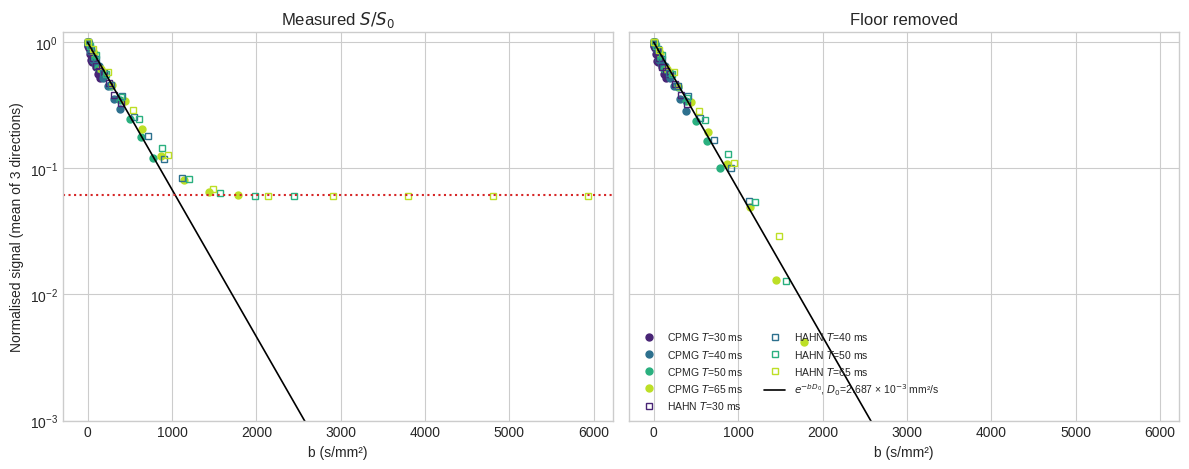

In [16]:
type_markers = {'CPMG': 'o', 'HAHN': 's'}
time_colors = dict(zip(sorted(data['td_ms'].unique()), plt.cm.viridis(np.linspace(0.1, 0.9, data['td_ms'].nunique()))))
b_fine = np.linspace(0, data['bvalue'].max(), 400)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.8), sharey=True)
for ax, column, title in zip(axes, ['value_norm', 'value_norm_corr'], ['Measured $S/S_0$', 'Floor removed']):
    for (sequence_type, td_ms), measurement in data.groupby(['type', 'td_ms'], sort=True):
        mean_curve = measurement.groupby('bvalue')[column].mean()
        ax.semilogy(mean_curve.index, mean_curve.to_numpy(), type_markers[sequence_type], color=time_colors[td_ms],
                    ms=5, mfc='none' if sequence_type == 'HAHN' else time_colors[td_ms],
                    label=f'{sequence_type} $T$={td_ms:g} ms')
    ax.semilogy(b_fine, np.exp(-b_fine * D0_REFERENCE), 'k-', lw=1.2, label=f'$e^{{-bD_0}}$, {d0_label(D0_REFERENCE)}')
    if column == 'value_norm':
        ax.axhline(FLOOR_F / data['S0'].mean(), color='tab:red', ls=':', lw=1.5, label=f'floor $c$={FLOOR_F / data["S0"].mean():.3f}')
    ax.set(title=title, xlabel='b (s/mm²)', ylim=(1e-3, 1.2))
axes[0].set_ylabel('Normalised signal (mean of 3 directions)')
axes[1].legend(fontsize=7.5, ncol=2, loc='lower left')
fig.tight_layout()
save_figure(fig, FLOOR_DIR, 'signal_vs_b_all_series')
plt.show()

## Fits: uncorrected and floor removed

The same fits as the original notebook, once with `value_norm` and once with `value_norm_corr`. Signal figures show the corrected points (filled) and the measured ones (open, grey) with the fit to the corrected points.

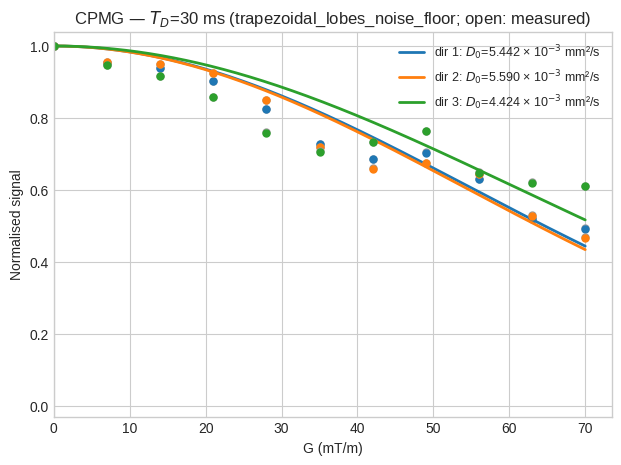

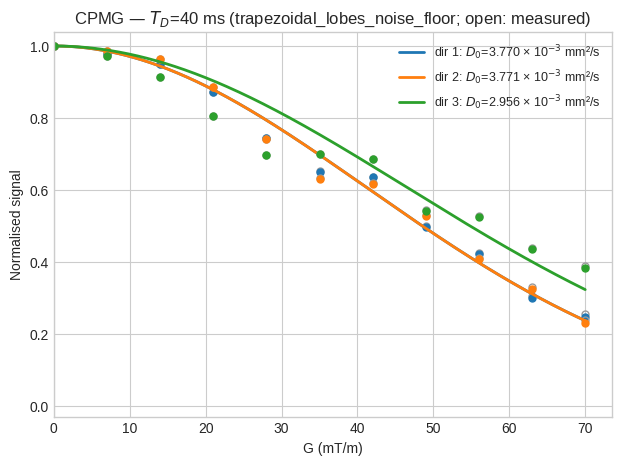

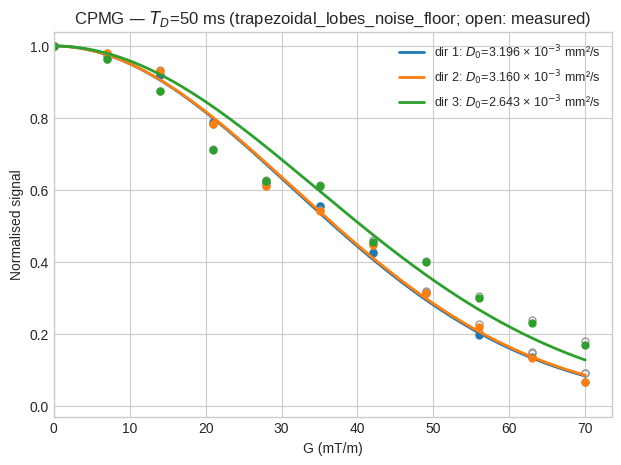

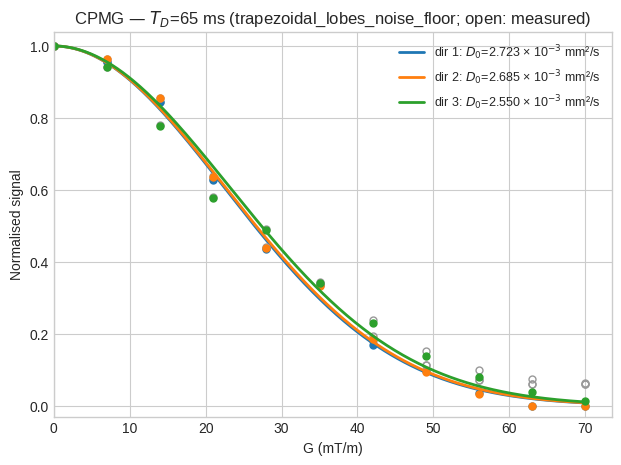

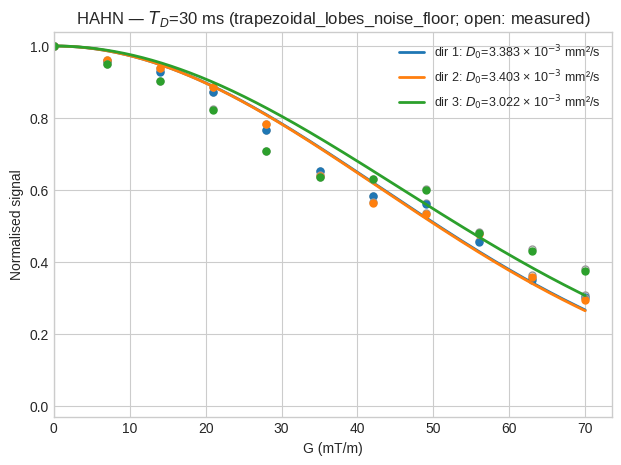

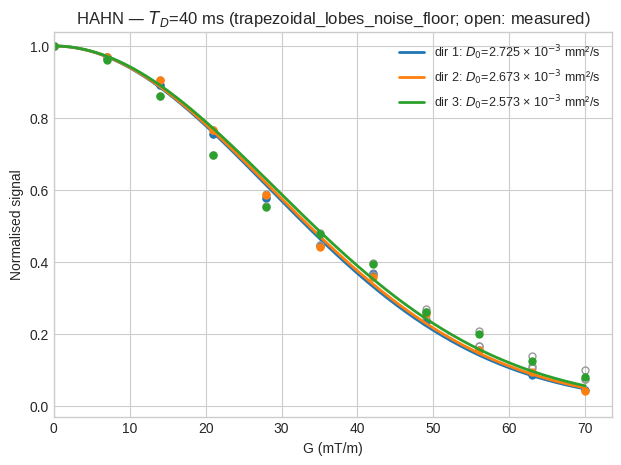

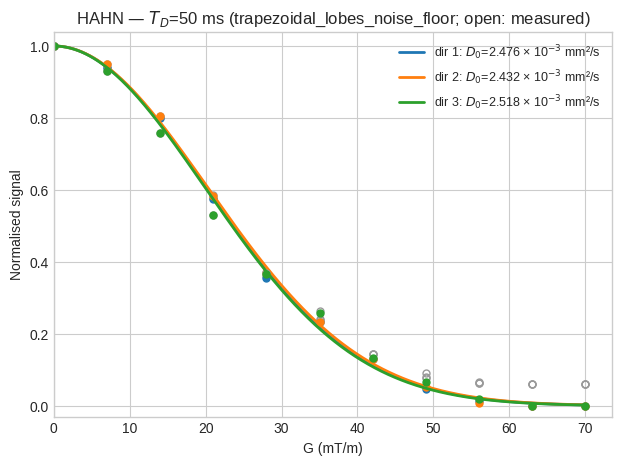

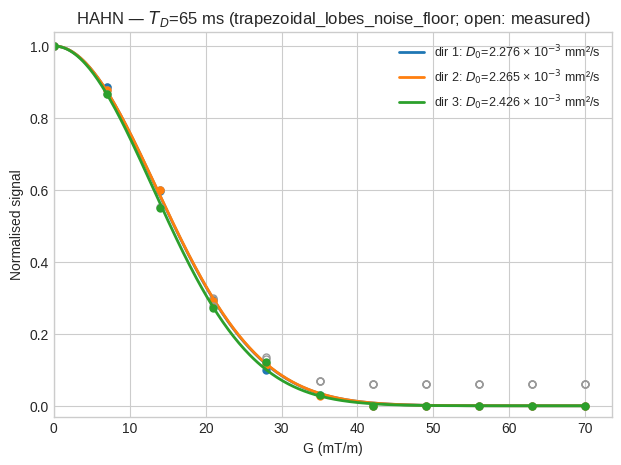

D0_mm2_s                      rmse            
correction floor_removed uncorrected floor_removed uncorrected
type td_ms                                                    
CPMG 30.0       0.005152    0.005118      0.055996    0.055900
     40.0       0.003499    0.003461      0.038925    0.039030
     50.0       0.002999    0.002935      0.032924    0.033122
     65.0       0.002652    0.002540      0.023729    0.031989
HAHN 30.0       0.003269    0.003237      0.044793    0.045100
     40.0       0.002657    0.002584      0.024862    0.028043
     50.0       0.002475    0.002365      0.014490    0.031924
     65.0       0.002322    0.002216      0.007108    0.041097

In [17]:
direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
DATA_COLUMNS = {'uncorrected': 'value_norm', 'floor_removed': 'value_norm_corr'}

signal_fit_rows = []
for (sequence_type, td_ms), measurement in data.groupby(['type', 'td_ms'], sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in measurement.groupby('direction', sort=True):
        curve = curve.sort_values('g')
        tn_ms, n_value, x_ms, ramp_ms = timing(curve)
        g = curve['g'].to_numpy(float)
        for correction, column in DATA_COLUMNS.items():
            fit = fit_one_parameter(curve[column].to_numpy(float),
                                    lambda d0: signal_model(tn_ms, g, n_value, x_ms, ramp_ms, d0))
            signal_fit_rows.append({
                'model': MODEL_NAME, 'correction': correction, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'roi': ROI,
                'type': sequence_type, 'td_ms': td_ms, 'direction': direction, 'N': n_value, 'x_ms': x_ms,
                'k_s_mm2_per_mT2_m2': k_model(tn_ms, n_value, x_ms, ramp_ms), **fit
            })
        color = direction_colors.get(direction)
        ax.plot(g, curve['value_norm'], 'o', color='0.6', mfc='none', ms=5)
        ax.plot(g, curve['value_norm_corr'], 'o', color=color, ms=5)
        g_fine = np.linspace(0, g.max(), 400)
        ax.plot(g_fine, signal_model(tn_ms, g_fine, n_value, x_ms, ramp_ms, fit['D0_mm2_s']),
                color=color, lw=2, label=f'dir {direction}: {d0_label(fit["D0_mm2_s"])}')
    ax.set(title=f'{sequence_type} — $T_D$={td_ms:g} ms ({OUTPUT_NAME}; open: measured)', xlabel='G (mT/m)',
           ylabel='Normalised signal', xlim=(0, None), ylim=(-0.03, 1.04))
    ax.legend(fontsize=9)
    save_figure(fig, SIGNAL_DIR, f'signal_{sequence_type}_Td-{td_ms:g}ms')
    plt.show()

signal_fits = pd.DataFrame(signal_fit_rows).sort_values(['correction', 'type', 'td_ms', 'direction'])
signal_fits.to_csv(TABLE_DIR / 'signal_fits.csv', index=False)
display(signal_fits.pivot_table(index=['type', 'td_ms'], columns='correction', values=['D0_mm2_s', 'rmse']))

## Contrast CPMG − Hahn

Points paired by time, direction and `b_step`, as in the original notebook; `value_contrast` and `value_contrast_corr` are the differences of the measured and of the corrected signals.

In [18]:
keys = ['td_ms', 'direction', 'b_step']
paired = ['g', 'bvalue', 'TN', 'N', 'x', 'ramp_time_ms', 'value_norm', 'value_norm_corr']
cpmg = data.loc[data['type'].eq('CPMG'), keys + paired].rename(columns={c: f'{c}_cpmg' for c in paired})
hahn = data.loc[data['type'].eq('HAHN'), keys + paired].rename(columns={c: f'{c}_hahn' for c in paired})
contrast = cpmg.merge(hahn, on=keys, how='inner', validate='one_to_one')
for column in ['g', 'TN', 'N']:  # the ramps may differ (Hahn 2 x CPMG, 2026-10-26)
    if not np.allclose(contrast[f'{column}_cpmg'], contrast[f'{column}_hahn'], rtol=1e-6, atol=1e-6):
        raise ValueError(f'CPMG and Hahn do not share {column} for every paired point.')
contrast['g'] = contrast['g_cpmg']
contrast['value_contrast'] = contrast['value_norm_cpmg'] - contrast['value_norm_hahn']
contrast['value_contrast_corr'] = contrast['value_norm_corr_cpmg'] - contrast['value_norm_corr_hahn']
CONTRAST_COLUMNS = {'uncorrected': 'value_contrast', 'floor_removed': 'value_contrast_corr'}


def contrast_timing(curve):
    row = curve.iloc[0]
    return (float(row['TN_cpmg']), float(row['N_cpmg']), float(row['x_cpmg']), float(row['x_hahn']),
            float(row['ramp_time_ms_cpmg']), float(row['ramp_time_ms_hahn']))


def expected_peak(tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0_mm2_s):
    # height and position of max(exp(-r u) - exp(-u)), u = k_Hahn G^2 D0, r = k_CPMG / k_Hahn
    k_hahn = k_model(tn_ms, n_value, x_hahn, ramp_hahn)
    r = k_model(tn_ms, n_value, x_cpmg, ramp_cpmg) / k_hahn
    u_star = np.log(1 / r) / (1 - r)
    return r, (1 - r) * r ** (r / (1 - r)), float(np.sqrt(u_star / (k_hahn * d0_mm2_s)))


contrast_fit_rows = []
for (td_ms, direction), curve in contrast.groupby(['td_ms', 'direction'], sort=True):
    curve = curve.sort_values('g')
    tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn = contrast_timing(curve)
    g = curve['g'].to_numpy(float)
    g_fine = np.linspace(0, g.max(), 2000)
    for correction, column in CONTRAST_COLUMNS.items():
        y = curve[column].to_numpy(float)
        fit = fit_one_parameter(y, lambda d0: contrast_model(tn_ms, g, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0))
        r, height, g_peak = expected_peak(tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, fit['D0_mm2_s'])
        contrast_fit_rows.append({
            'model': MODEL_NAME, 'correction': correction, 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'roi': ROI,
            'td_ms': td_ms, 'direction': direction, 'N': n_value, 'x_cpmg_ms': x_cpmg, 'x_hahn_ms': x_hahn,
            'k_ratio_cpmg_over_hahn': r, 'peak_expected': height, 'G_peak_expected_mT_m': g_peak,
            'peak_in_range': bool(g_peak <= g.max()), 'peak_data_max': float(y.max()),
            'G_at_data_max': float(g[y.argmax()]),
            'peak_fit_in_range': float(contrast_model(tn_ms, g_fine, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, fit['D0_mm2_s']).max()),
            **fit
        })

contrast_fits = pd.DataFrame(contrast_fit_rows).sort_values(['correction', 'td_ms', 'direction'])
contrast_fits.to_csv(TABLE_DIR / 'contrast_fits.csv', index=False)
display(contrast_fits.pivot_table(index='td_ms', columns='correction', values=['D0_mm2_s', 'rmse', 'peak_data_max']))

D0_mm2_s             peak_data_max                      rmse  \
correction floor_removed uncorrected floor_removed uncorrected floor_removed   
td_ms                                                                          
30.0            0.001273    0.001256      0.198284    0.195713      0.013184   
40.0            0.001045    0.000969      0.289352    0.284826      0.056497   
50.0            0.002710    0.003121      0.331524    0.324561      0.052151   
65.0            0.002464    0.002844      0.349157    0.342409      0.032622   

                        
correction uncorrected  
td_ms                   
30.0          0.013398  
40.0          0.062064  
50.0          0.060261  
65.0          0.039182

### Contrasts: four times for each direction, and the three directions at each time

Filled: floor removed, with its fit. Open grey: measured contrast. Dashed horizontal ticks: expected peak height $H(r)$ for the played timing ($T=30$ ms peaks at $\approx96$ mT/m, outside the measured range).

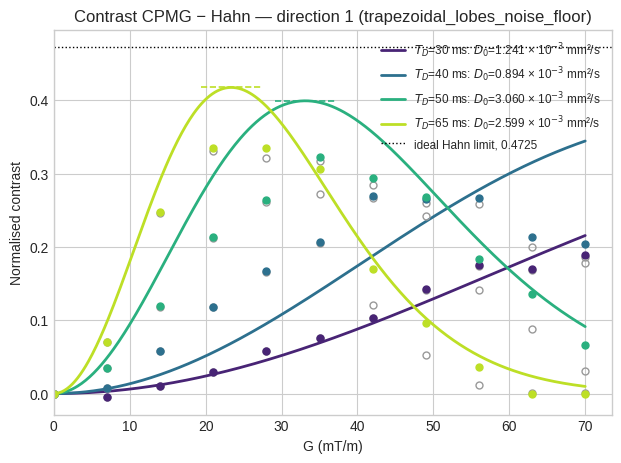

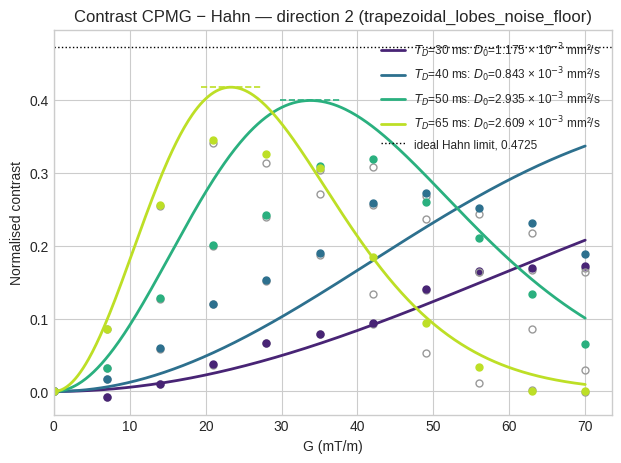

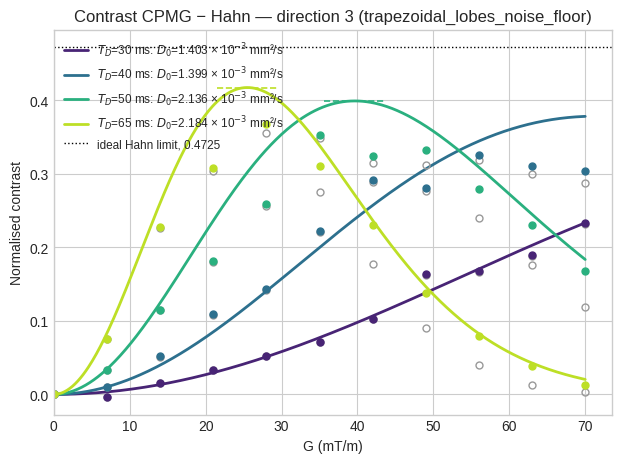

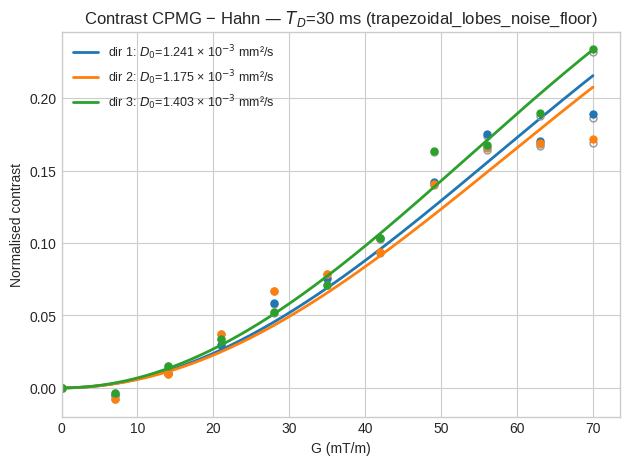

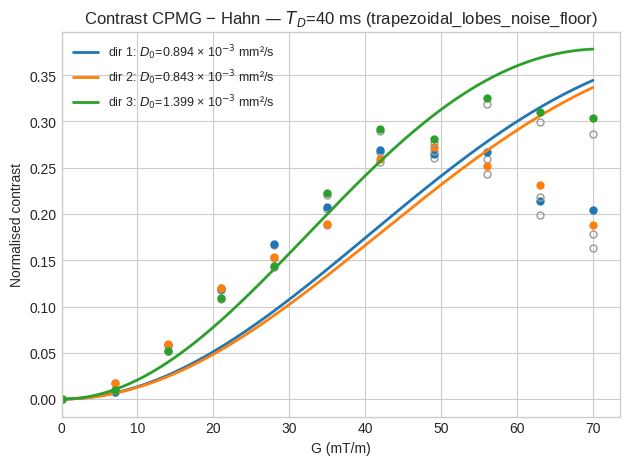

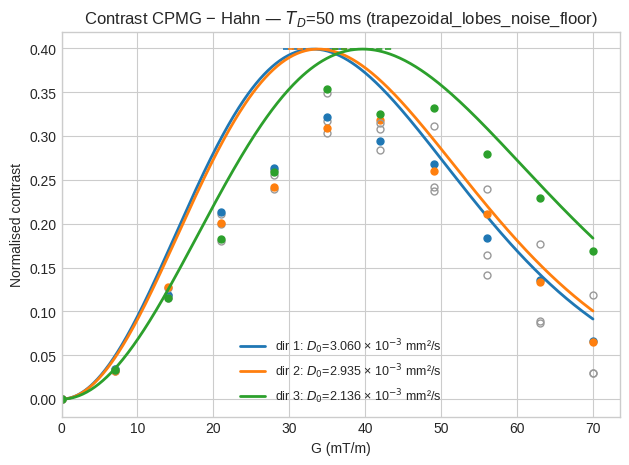

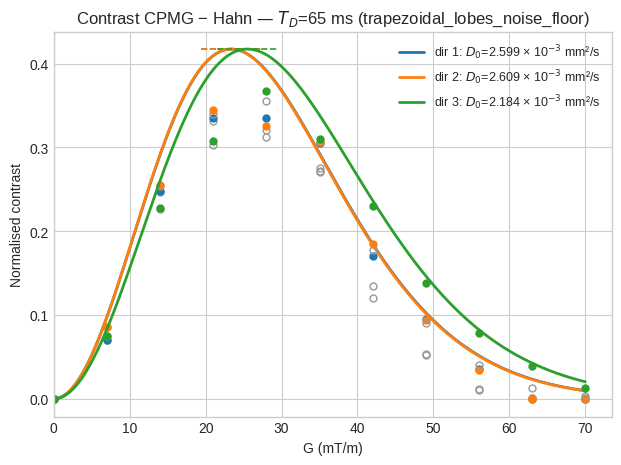

In [19]:
def contrast_d0(td_ms, direction, correction='floor_removed'):
    return contrast_fits.loc[contrast_fits['td_ms'].eq(td_ms) & contrast_fits['direction'].eq(direction) &
                             contrast_fits['correction'].eq(correction), 'D0_mm2_s'].iloc[0]


def plot_contrast_curve(ax, curve, d0, color, label, show_expected=True):
    curve = curve.sort_values('g')
    tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn = contrast_timing(curve)
    ax.plot(curve['g'], curve['value_contrast'], 'o', color='0.6', mfc='none', ms=5)
    ax.plot(curve['g'], curve['value_contrast_corr'], 'o', color=color, ms=5)
    g_fine = np.linspace(0, curve['g'].max(), 400)
    ax.plot(g_fine, contrast_model(tn_ms, g_fine, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0), color=color, lw=2,
            label=f'{label}: {d0_label(d0)}')
    _, height, g_peak = expected_peak(tn_ms, n_value, x_cpmg, x_hahn, ramp_cpmg, ramp_hahn, d0)
    if show_expected and g_peak <= curve['g'].max():
        ax.plot([g_peak - 4, g_peak + 4], [height, height], '--', color=color, lw=1.2)


for direction, panel in contrast.groupby('direction', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for td_ms, curve in panel.groupby('td_ms', sort=True):
        plot_contrast_curve(ax, curve, contrast_d0(td_ms, direction), time_colors[td_ms], f'$T_D$={td_ms:g} ms')
    ax.axhline(IDEAL_PEAK, color='k', ls=':', lw=1, label='ideal Hahn limit, 0.4725')
    ax.set(title=f'Contrast CPMG − Hahn — direction {direction} ({OUTPUT_NAME})', xlabel='G (mT/m)',
           ylabel='Normalised contrast', xlim=(0, None))
    ax.legend(fontsize=8.5)
    save_figure(fig, CONTRAST_DIRECTION_DIR, f'contrast_direction-{direction}')
    plt.show()

for td_ms, panel in contrast.groupby('td_ms', sort=True):
    fig, ax = plt.subplots(figsize=(7.2, 5.0))
    for direction, curve in panel.groupby('direction', sort=True):
        plot_contrast_curve(ax, curve, contrast_d0(td_ms, direction), direction_colors.get(direction), f'dir {direction}')
    ax.set(title=f'Contrast CPMG − Hahn — $T_D$={td_ms:g} ms ({OUTPUT_NAME})', xlabel='G (mT/m)',
           ylabel='Normalised contrast', xlim=(0, None))
    ax.legend(fontsize=9)
    save_figure(fig, CONTRAST_TIME_DIR, f'contrast_Td-{td_ms:g}ms')
    plt.show()

## Check 1: floor inside the model, all curves at once

No plateau selection and no correction of the data: per direction, the 8 measured curves (4 times × CPMG/Hahn, 88 points) are fitted together with one $D_0$ and

- `none`: $s=a$,
- `quadrature`: $s=\sqrt{a^2+c^2}/\sqrt{1+c^2}$ (magnitude noise floor),
- `additive`: $s=(a+f)/(1+f)$ (a fraction $f$ of signal that does not decay),

with $a=e^{-kG^2D_0}$. If the plateau is a noise floor, `quadrature` must fit best and return $c\approx F/S_0$.

In [20]:
def joint_model(kind, params, k_values, g_values):
    a = np.exp(-k_values * g_values**2 * params[0] * 1e-3)
    if kind == 'none':
        return a
    if kind == 'quadrature':
        return np.sqrt(a**2 + params[1]**2) / np.sqrt(1 + params[1]**2)
    return (a + params[1]) / (1 + params[1])


data['k'] = [k_model(row.TN, row.N, row.x, row.ramp_time_ms) for row in data.itertuples()]
joint_rows = []
for direction, curves in data.groupby('direction', sort=True):
    k_values, g_values, y = (curves[c].to_numpy(float) for c in ('k', 'g', 'value_norm'))
    for kind, start in (('none', [2.1]), ('quadrature', [2.1, 0.03]), ('additive', [2.1, 0.03])):
        result = least_squares(lambda p: joint_model(kind, p, k_values, g_values) - y, start)
        joint_rows.append({'direction': direction, 'floor_model': kind, 'D0_mm2_s': result.x[0] * 1e-3,
                           'c_or_f': result.x[1] if len(result.x) > 1 else np.nan,
                           'rmse': float(np.sqrt(np.mean(result.fun**2))), 'max_abs_residual': float(np.abs(result.fun).max()),
                           'n_points': len(y)})
joint_fits = pd.DataFrame(joint_rows)
joint_fits.to_csv(TABLE_DIR / 'joint_floor_model_fits.csv', index=False)
display(joint_fits)
print(f'c from the plateau: {FLOOR_F / data["S0"].mean():.4f}')

,direction,floor_model,D0_mm2_s,c_or_f,rmse,max_abs_residual,n_points
0,1,none,0.003068,NaN,0.060816,0.167106,88
1,1,quadrature,0.003213,0.080253,0.054233,0.158937,88
2,1,additive,0.003629,0.082051,0.051816,0.154098,88
3,2,none,0.003049,NaN,0.063585,0.188812,88
4,2,quadrature,0.003198,0.081347,0.057261,0.183189,88
5,2,additive,0.003621,0.083670,0.054776,0.176787,88
6,3,none,0.002722,NaN,0.064429,0.196373,88
7,3,quadrature,0.002890,0.091718,0.057684,0.191626,88
8,3,additive,0.003344,0.098821,0.053823,0.186203,88


c from the plateau: 0.0617


## Contrast peaks: measured against expected

`peak_expected` is $H(r)$ for the played timing ($x_{Hahn}=5$ ms, trapezoids), `peak_fit_in_range` the maximum of the fitted curve inside the measured $G$ range and `peak_data_max` the largest measured point (the $G$ grid is 7 mT/m, so it can sit slightly below the true maximum). At $T=30$ ms the peak is outside the range and only a lower bound is measured.

,correction,td_ms,k_ratio,peak_expected,G_peak_expected,peak_in_range,peak_fit_in_range,peak_data_max,peak_data_sd,data_over_expected
0,floor_removed,30.0,0.381578,0.341282,124.065521,False,0.218855,0.198284,0.032003,0.580997
1,floor_removed,40.0,0.340171,0.378443,84.187517,False,0.353102,0.289352,0.031598,0.764584
2,floor_removed,50.0,0.318541,0.399209,35.535064,True,0.399209,0.331524,0.019141,0.830454
3,floor_removed,65.0,0.300388,0.417439,24.066224,True,0.417439,0.349157,0.016285,0.836426
4,uncorrected,30.0,0.381578,0.341282,124.876393,False,0.216976,0.195713,0.032195,0.573462
5,uncorrected,40.0,0.340171,0.378443,87.747668,False,0.344204,0.284826,0.029881,0.752626
6,uncorrected,50.0,0.318541,0.399209,33.080522,True,0.399208,0.324561,0.021256,0.813012
7,uncorrected,65.0,0.300388,0.417439,22.383959,True,0.417439,0.342409,0.012049,0.820260


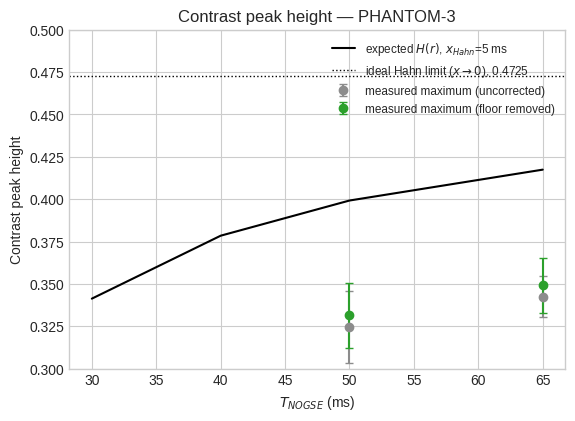

In [21]:
peaks = contrast_fits.groupby(['correction', 'td_ms']).agg(
    k_ratio=('k_ratio_cpmg_over_hahn', 'first'), peak_expected=('peak_expected', 'mean'),
    G_peak_expected=('G_peak_expected_mT_m', 'mean'), peak_in_range=('peak_in_range', 'all'),
    peak_fit_in_range=('peak_fit_in_range', 'mean'), peak_data_max=('peak_data_max', 'mean'),
    peak_data_sd=('peak_data_max', 'std')).reset_index()
peaks['data_over_expected'] = peaks['peak_data_max'] / peaks['peak_expected']
peaks.to_csv(TABLE_DIR / 'contrast_peaks.csv', index=False)
display(peaks)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
expected = peaks.loc[peaks['correction'].eq('floor_removed')]
ax.plot(expected['td_ms'], expected['peak_expected'], 'k-', lw=1.5, label='expected $H(r)$, $x_{Hahn}$=5 ms')
for correction, color in (('uncorrected', '0.55'), ('floor_removed', 'tab:green')):
    rows = peaks.loc[peaks['correction'].eq(correction) & peaks['peak_in_range']]
    ax.errorbar(rows['td_ms'], rows['peak_data_max'], yerr=rows['peak_data_sd'], fmt='o', color=color, capsize=3,
                label=f'measured maximum ({correction.replace("_", " ")})')
ax.axhline(IDEAL_PEAK, color='k', ls=':', lw=1, label='ideal Hahn limit ($x\\to0$), 0.4725')
ax.set(xlabel='$T_{NOGSE}$ (ms)', ylabel='Contrast peak height', ylim=(0.3, 0.5),
       title=f'Contrast peak height — {SUB}')
ax.legend(fontsize=8.5)
save_figure(fig, FLOOR_DIR, 'contrast_peak_heights')
plt.show()

## Summary: $D_0$ against $T$

Mean over the three directions of every fitted $D_0$ (×10⁻³ mm²/s). For free water $D_0$ must not depend on $T$ nor on the modulation; `CV_over_T_%` is the coefficient of variation across the four times.

td_ms                      30.0    40.0    50.0    65.0  CV_over_T_%
correction    curve                                                 
floor_removed CPMG       5.1523  3.4992  2.9994  2.6524      30.9562
              CPMG-HAHN  1.2728  1.0453  2.7103  2.4640      44.6207
              HAHN       3.2692  2.6567  2.4753  2.3224      15.4916
uncorrected   CPMG       5.1181  3.4609  2.9354  2.5396      32.2852
              CPMG-HAHN  1.2565  0.9686  3.1206  2.8443      53.3248
              HAHN       3.2371  2.5840  2.3649  2.2160      17.3241

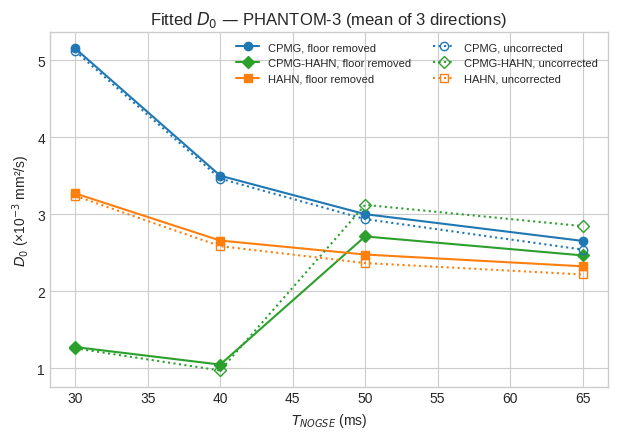

Figures and tables saved in: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/trapezoidal_lobes_noise_floor/sub-PHANTOM-3/ses-20261026NOGSEV2001FOV220M128SL01R1G070AUTOG/roi-water2


In [22]:
summary = pd.concat([
    signal_fits.assign(curve=signal_fits['type']),
    contrast_fits.assign(curve='CPMG-HAHN'),
]).groupby(['correction', 'curve', 'td_ms'])['D0_mm2_s'].mean().mul(1e3).unstack('td_ms')
summary['CV_over_T_%'] = 100 * summary.std(axis=1, ddof=1) / summary.mean(axis=1)
summary.to_csv(TABLE_DIR / 'D0_summary_1e-3_mm2_s.csv')
display(summary.round(4))

fig, ax = plt.subplots(figsize=(7.2, 4.6))
styles = {'CPMG': ('tab:blue', 'o'), 'HAHN': ('tab:orange', 's'), 'CPMG-HAHN': ('tab:green', 'D')}
for (correction, curve), row in summary.drop(columns='CV_over_T_%').iterrows():
    color, marker = styles[curve]
    ax.plot(row.index, row.to_numpy(), marker=marker, color=color, ls='-' if correction == 'floor_removed' else ':',
            mfc=color if correction == 'floor_removed' else 'none', label=f'{curve}, {correction.replace("_", " ")}')
ax.set(xlabel='$T_{NOGSE}$ (ms)', ylabel='$D_0$ (×10$^{-3}$ mm²/s)', title=f'Fitted $D_0$ — {SUB} (mean of 3 directions)')
ax.legend(fontsize=8, ncol=2)
save_figure(fig, FLOOR_DIR, 'D0_vs_T')
plt.show()
print('Figures and tables saved in:', OUTPUT_ROOT)